<!-- open-in-badges -->
[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/03_vision/notebooks/sesion_03_6_integrador_eurosat.ipynb) [![Abrir en Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/03_vision/notebooks/sesion_03_6_integrador_eurosat.ipynb) [![Abrir en Lightning Studio](https://pl-bolts-doc-images.s3.us-east-2.amazonaws.com/app-2/studio-badge.svg)](https://lightning.ai/new?repo_url=https%3A%2F%2Fgithub.com%2FEAFIT-IA%2Fsi7011-DeepLearning%2Fblob%2Fmain%2Fsessions%2F03_vision%2Fnotebooks%2Fsesion_03_6_integrador_eurosat.ipynb)

# SI7011 · Sesión 03 · Ejercicio integrador: ¿ImageNet sirve para mirar la Tierra desde el espacio?
**Juan David Martínez Vargas · Universidad EAFIT**

En los notebooks 1–5 cada pieza apareció sola: la CNN, BatchNorm, los residuales, la augmentation, el transfer learning. Aquí **las combinas** sobre datos nuevos y registras cada corrida en MLflow, como en el integrador de la sesión 02. Cada TODO indica en qué notebook está la pieza.

**Datos: EuroSAT.** 27 000 imágenes del satélite Sentinel-2, de 64×64 píxeles en RGB, etiquetadas con **10 usos del suelo**: cultivos, bosque, autopista, río, zona residencial, mar o lago, entre otros. Son fotos tomadas desde arriba: no se parecen a las de ImageNet (diapositiva *When transfer helps less*).

| Etapa | Qué haces | Artefacto |
|---|---|---|
| Datos | validar el contrato, partir sin fuga y elegir una augmentation que respete el dominio (**TODO 1**) | `data_card.json` |
| Entrenamiento | tu modelo (**TODO 2**) y tu optimizador (**TODO 3**); 3 corridas en MLflow | `best.pt` por corrida |
| Despliegue | predecir sobre imágenes crudas desde MLflow (**TODO 4**) | `predicciones.csv` |

**Duración:** 60–75 min. **Entorno:** Kaggle con GPU (agrega el dataset [`apollo2506/eurosat-dataset`](https://www.kaggle.com/datasets/apollo2506/eurosat-dataset) con **Add Input**) o Colab con GPU (lo descarga con tu secreto `KAGGLE_API_TOKEN`). En CPU usa `TRAIN_SIZE = 5_000`.

In [1]:
%pip install -q mlflow

In [2]:
import copy, hashlib, json, math, os, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn
from torchvision import datasets, transforms
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix

os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')
import mlflow

torch.manual_seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('PyTorch', torch.__version__, '· MLflow', mlflow.__version__, '· device', device)

PyTorch 2.14.1+cu130 · MLflow 3.18.0 · device cuda


In [3]:
# Registro limpio: borra corridas de ejecuciones anteriores para que MLflow tenga solo las 3 de este notebook
import shutil
for p in ['mlflow.db', 'mlruns', 'best.pt', 'predicciones.csv']:
    if os.path.isdir(p): shutil.rmtree(p)
    elif os.path.exists(p): os.remove(p)
print('Registro de MLflow limpio')


Registro de MLflow limpio


## 1. Datos: contrato y ficha (listo)
El **contrato** dice qué acepta el modelo: imágenes RGB de 64×64 y una de las 10 clases. Se valida al cargar y se vuelve a validar al predecir. La **ficha** (*data card*) registra de dónde salieron los datos y se guarda con cada corrida.

In [4]:
KAGGLE_HANDLE = 'apollo2506/eurosat-dataset'
ROOTS = [Path('data'), Path('/kaggle/input'), Path('/teamspace/studios/this_studio/data')]

def kaggle_token():
    # Colab: secreto KAGGLE_API_TOKEN. Local o Lightning: variable de entorno o ~/.kaggle/access_token.
    if 'KAGGLE_API_TOKEN' not in os.environ:
        try:
            from google.colab import userdata
            os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN').strip()
        except Exception:
            pass
    return 'KAGGLE_API_TOKEN' in os.environ or (Path.home() / '.kaggle' / 'access_token').exists()

def find_rgb(roots):
    # El dataset trae EuroSAT/ (JPG, RGB) y EuroSATallBands/ (TIFF de 13 bandas): solo sirve la carpeta con JPG
    for root in [r for r in roots if r.exists()]:
        for d in sorted(root.rglob('AnnualCrop')):
            if d.is_dir() and next(d.glob('*.jpg'), None) is not None:
                return d.parent
    return None

def load_eurosat():
    folder = find_rgb(ROOTS)
    if folder is None and (kaggle_token() or Path('/kaggle/input').exists()):
        try:
            import kagglehub                               # preinstalado en Colab y Kaggle
            folder = find_rgb([Path(kagglehub.dataset_download(KAGGLE_HANDLE))])
        except Exception as e:
            print('kagglehub no disponible:', type(e).__name__, '→ se descarga con torchvision')
    if folder is not None:
        print('Leyendo', folder); return datasets.ImageFolder(folder), str(folder)
    print('EuroSAT no encontrado en disco: descargando con torchvision.datasets.EuroSAT')
    return datasets.EuroSAT('data', download=True), 'torchvision.datasets.EuroSAT'

ds, src = load_eurosat()
CLASSES = ds.classes; C = len(CLASSES)
CONTRACT = {'mode': 'RGB', 'size': [64, 64], 'classes': CLASSES}

# el mismo contrato se aplica al cargar los datos y al predecir (TODO 4)
def validate_image(img, contract=CONTRACT):
    if img.mode != contract['mode']:
        raise ValueError(f"Se esperaba una imagen {contract['mode']}, llegó {img.mode}.")
    if list(img.size) != contract['size']:
        raise ValueError(f"Se esperaba {contract['size']}, llegó {list(img.size)}.")
    return torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1)        # uint8, 3 × 64 × 64

t0 = time.time()
X_all = torch.stack([validate_image(ds[i][0]) for i in range(len(ds))])
y_all = torch.tensor([label for _, label in ds.samples])
names = sorted(Path(p).name for p, _ in ds.samples)
data_card = {'fuente': src, 'sha256_nombres': hashlib.sha256('\n'.join(names).encode()).hexdigest()[:16],
             'imagenes': len(ds), 'clases': dict(zip(CLASSES, np.bincount(y_all, minlength=C).tolist()))}
json.dump(data_card, open('data_card.json', 'w'), indent=1)
print(f'{len(X_all)} imágenes en {time.time() - t0:.0f} s'); data_card

Using Colab cache for faster access to the 'eurosat-dataset' dataset.
Leyendo /kaggle/input/eurosat-dataset/EuroSAT
27000 imágenes en 166 s


{'fuente': '/kaggle/input/eurosat-dataset/EuroSAT',
 'sha256_nombres': '41025a8d575789c1',
 'imagenes': 27000,
 'clases': {'AnnualCrop': 3000,
  'Forest': 3000,
  'HerbaceousVegetation': 3000,
  'Highway': 2500,
  'Industrial': 2500,
  'Pasture': 2000,
  'PermanentCrop': 2500,
  'Residential': 3000,
  'River': 2500,
  'SeaLake': 3000}}

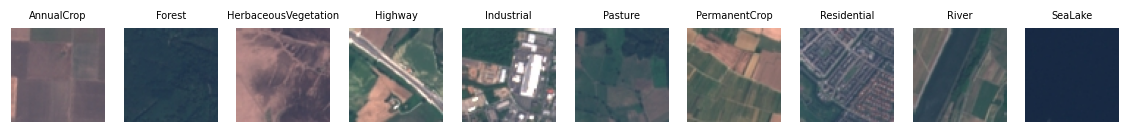

In [5]:
fig, axes = plt.subplots(1, C, figsize=(13, 1.8))
for c, ax in enumerate(axes):
    ax.imshow(X_all[(y_all == c).nonzero()[0, 0]].permute(1, 2, 0)); ax.set_title(CLASSES[c], fontsize=6.5); ax.axis('off')
plt.show()

Las clases están casi balanceadas, pero no del todo. Reportamos la accuracy y también el **F1 macro**, como en Covertype.

La normalización es la de ImageNet para todos los modelos, también para el que se entrena desde cero, y viaja dentro de cada `best.pt`.

In [6]:
MEAN = ResNet18_Weights.IMAGENET1K_V1.transforms().mean
STD = ResNet18_Weights.IMAGENET1K_V1.transforms().std
_m, _s = torch.tensor(MEAN, device=device).view(1, 3, 1, 1), torch.tensor(STD, device=device).view(1, 3, 1, 1)
prep = lambda xb: (xb.to(device).float() / 255 - _m) / _s   # (x/255 − μ)/s con μ, s de ImageNet (notebook 4)

## 2. TODO 1 · Partición y augmentation · 10 min
1. Haz una partición **estratificada** 70/15/15 de los índices (entrenamiento/validación/prueba) con `random_state=0`. Si `TRAIN_SIZE` no es `None`, toma una submuestra de ese tamaño del entrenamiento.
2. Escribe `augment(xb)`: recibe un lote normalizado $N \times 3 \times 64 \times 64$ y devuelve uno del mismo tamaño. Elige transformaciones que **no cambien la clase de una imagen satelital**. Piensa en el *Tu turno* 3 del notebook 3: lo que estaba mal en CIFAR-10, ¿está mal aquí?

No hay estadísticas que calcular con entrenamiento: la normalización es fija. La fuga que hay que evitar aquí es que una misma imagen quede en dos particiones.

In [7]:
TRAIN_SIZE = None            # en CPU: 5_000
idx_all = np.arange(len(y_all))
y_np = y_all.numpy()

# TODO 1: idx_train, idx_val, idx_test y la función augment(xb)
# 1. Partición estratificada 70/15/15 de los índices: cada imagen queda en una sola partición
idx_trval, idx_test = train_test_split(idx_all, test_size=0.15, random_state=0, stratify=y_np)
idx_train, idx_val = train_test_split(idx_trval, test_size=0.15 / 0.85, random_state=0, stratify=y_np[idx_trval])
if TRAIN_SIZE is not None:
    idx_train, _ = train_test_split(idx_train, train_size=TRAIN_SIZE, random_state=0, stratify=y_np[idx_train])

# 2. Augmentation. Una imagen satelital se toma desde arriba: no hay un "arriba" ni un "abajo" en la escena.
#    Un bosque, un río o una autopista siguen siendo lo mismo si la imagen se rota 90° o se refleja,
#    así que se usan las 8 orientaciones del cuadrado (rotaciones de 90° + espejo) y una traslación pequeña.
#    No se cambian los colores: el color distingue clases (cultivo, pasto, mar) y la normalización es fija.
def augment(xb, pad=4):
    n, dev = len(xb), xb.device
    # espejo horizontal con probabilidad 1/2
    flip = torch.rand(n, device=dev) < 0.5
    xb = torch.where(flip.view(-1, 1, 1, 1), xb.flip(3), xb)
    # rotación de 0°, 90°, 180° o 270° al azar (con el espejo dan las 8 orientaciones)
    k = torch.randint(0, 4, (n,), device=dev)
    out = xb.clone()
    for r in range(1, 4):
        sel = k == r
        if sel.any():
            out[sel] = torch.rot90(xb[sel], r, dims=(2, 3))
    # traslación de hasta ±4 píxeles: bordes por reflexión y recorte de 64×64 (notebook 3, sección 3)
    padded = F.pad(out, (pad, pad, pad, pad), mode='reflect')
    ij = torch.randint(0, 2 * pad + 1, (n, 2)).tolist()
    return torch.stack([padded[m, :, i:i + 64, j:j + 64] for m, (i, j) in enumerate(ij)])


entrenamiento 18899 · validación 4051 · prueba 4050


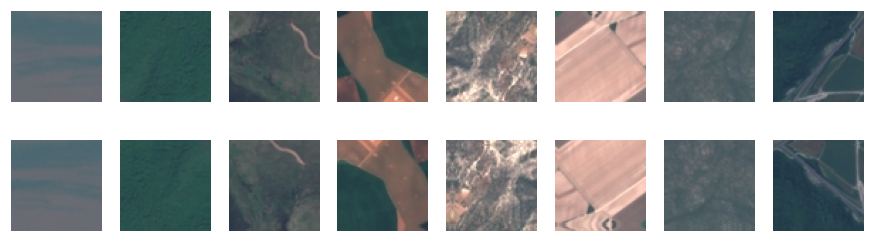

In [8]:
assert not (set(idx_train) & set(idx_val)) and not (set(idx_train) & set(idx_test)) and not (set(idx_val) & set(idx_test))
props = lambda idx: np.bincount(y_all[idx], minlength=C) / len(idx)
assert np.abs(props(idx_val) - props(idx_test)).max() < 0.01, 'Esperaba una partición estratificada.'
xb = prep(X_all[idx_train[:16]])
xa = augment(xb)
assert xa.shape == xb.shape, 'augment debe devolver un lote del mismo tamaño.'
assert not torch.allclose(xa, xb), 'augment no cambió nada.'
X_train, y_train = X_all[idx_train], y_all[idx_train]
X_val, y_val = X_all[idx_val], y_all[idx_val]
X_test, y_test = X_all[idx_test], y_all[idx_test]
print('entrenamiento', len(y_train), '· validación', len(y_val), '· prueba', len(y_test))

show = lambda t: (t.cpu() * _s.cpu()[0] + _m.cpu()[0]).clamp(0, 1).permute(1, 2, 0)
fig, axes = plt.subplots(2, 8, figsize=(10, 2.8))
for k in range(8):
    axes[0, k].imshow(show(xb[k])); axes[1, k].imshow(show(xa[k]))
for ax in axes.flat: ax.axis('off')
plt.show()

## 3. El loop y MLflow (listo)
`train_epoch` es el loop del notebook 3 con *scheduler* y la norma del gradiente. `run` hace lo mismo que en el integrador de la sesión 02:

- registra en **MLflow** los parámetros, las curvas por época, la pérdida inicial y la norma del gradiente;
- aplica **early stopping** sobre `val_loss`;
- guarda `best.pt` con los pesos **y** todo lo necesario para predecir: el nombre del constructor del modelo, la normalización y el contrato.

`before_epoch` permite, por ejemplo, congelar BatchNorm en cada época (notebook 4, sección 4).

In [9]:
loss_fn = nn.CrossEntropyLoss()  # L_i = −log softmax(f_θ(x_i))_{y_i}; recibe logits
BATCH = 128

def train_epoch(model, opt, scheduler=None, before_epoch=None):
    model.train()
    if before_epoch is not None:
        before_epoch(model)  # p. ej. freeze_bn (notebook 4, sección 4)
    perm = torch.randperm(len(y_train))
    total, norms = 0.0, []
    for i in range(0, len(perm), BATCH):
        b = perm[i:i + BATCH]
        # J_𝓑(θ) sobre el lote aumentado: tu augment del TODO 1, solo en entrenamiento (notebook 3, sección 3)
        loss = loss_fn(model(augment(prep(X_train[b]))), y_train[b].to(device))
        opt.zero_grad(); loss.backward()  # g_t = ∇_θ J_𝓑
        # ‖g_t‖ sin recortar (sesión 02, notebook 2, sección 6)
        norms.append(nn.utils.clip_grad_norm_(model.parameters(), float('inf')).item())
        opt.step()
        if scheduler is not None:
            scheduler.step()  # η_t = s(t) · η_0 en cada grupo (notebook 4, sección 4)
        total += loss.item() * len(b)
    return total / len(perm), float(np.mean(norms))

@torch.no_grad()
def evaluate(model, X, y, chunk=512):
    model.eval()  # Dropout apagado, BatchNorm con promedios móviles
    logits = torch.cat([model(prep(X[i:i + chunk])).float().cpu() for i in range(0, len(X), chunk)])
    pred = logits.argmax(1)
    return {'loss': loss_fn(logits, y).item(), 'acc': (pred == y).float().mean().item(),
            'macro_f1': f1_score(y, pred, average='macro', zero_division=0)}, pred.numpy()

In [10]:
mlflow.set_tracking_uri('sqlite:///mlflow.db')
EXPERIMENT = 'S03-eurosat'
mlflow.set_experiment(EXPERIMENT)

def run(name, build_model, make_opt, params, epochs=8, patience=3, before_epoch=None):
    torch.manual_seed(0)
    model = build_model().to(device)
    opt, scheduler = make_opt(model, epochs * math.ceil(len(y_train) / BATCH))
    with mlflow.start_run(run_name=name):
        mlflow.log_params({**params, 'epochs': epochs, 'patience': patience, 'train_size': len(y_train),
                           'n_params': sum(p.numel() for p in model.parameters()),
                           'n_trainable': sum(p.numel() for p in model.parameters() if p.requires_grad)})
        mlflow.log_dict(data_card, 'data_card.json')
        mlflow.log_metric('init_loss', evaluate(model, X_val, y_val)[0]['loss'])
        best, best_state, bad = {'val_loss': float('inf')}, None, 0
        for epoch in range(epochs):
            t0 = time.time()
            train_loss, grad_norm = train_epoch(model, opt, scheduler, before_epoch)
            va, _ = evaluate(model, X_val, y_val)
            row = {'train_loss': train_loss, 'grad_norm': grad_norm, 'lr': opt.param_groups[-1]['lr'],
                   'val_loss': va['loss'], 'val_acc': va['acc'], 'val_macro_f1': va['macro_f1'], 'epoch_s': time.time() - t0}
            if not math.isfinite(train_loss):
                mlflow.set_tag('status', 'diverged'); print('  diverge: se detiene'); break
            mlflow.log_metrics(row, step=epoch)
            # early stopping: θ* = argmin_t J_val(θ_t) (sesión 02, notebook 3, sección 4)
            if row['val_loss'] < best['val_loss']:
                best, best_state, bad = {**row, 'epoch': epoch}, copy.deepcopy(model.state_dict()), 0
            else:
                bad += 1
            if bad == patience:
                mlflow.set_tag('early_stopped', epoch); break
        print(f"{name}: mejor época {best.get('epoch')} · val_loss {best['val_loss']:.4f} · "
              f"val_acc {best.get('val_acc', 0):.3f} · F1 macro {best.get('val_macro_f1', 0):.3f}")
        if best_state is not None:
            mlflow.log_metrics({'best_epoch': best['epoch'], 'best_val_loss': best['val_loss'],
                                'best_val_acc': best['val_acc'], 'best_val_macro_f1': best['val_macro_f1']})
            # best.pt lleva todo lo necesario para predecir: constructor, θ*, normalización y contrato
            torch.save({'model': build_model.__name__, 'state_dict': best_state, 'mean': MEAN, 'std': STD,
                        'contract': CONTRACT}, 'best.pt')
            mlflow.log_artifact('best.pt')
    return model

2026/11/24 18:42:31 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/24 18:42:32 INFO mlflow.store.db.utils: Updating database tables
2026/11/24 18:42:34 INFO mlflow.tracking.fluent: Experiment with name 'S03-eurosat' does not exist. Creating a new experiment.


## 4. Corrida 1 · Línea base: una CNN desde cero (lista)
La red con bloques VGG y BatchNorm del notebook 3, con 32, 64 y 128 canales para imágenes de 64×64, entrenada desde cero con Adam. Antes de correrla, **predice** su accuracy de validación.

*Predicción:* una `val_acc` alrededor de **0.90**. EuroSAT tiene unas 19 000 imágenes de entrenamiento, 10 clases casi balanceadas y clases que se distinguen sobre todo por **textura y color** (bosque, mar, cultivo), que es justo lo que aprenden bien las primeras convoluciones. Por eso una CNN pequeña con BatchNorm y augmentation debería aprender bien desde cero. No espero que llegue al nivel del transfer learning: en 8 épocas no alcanza a aprender filtros tan ricos como los de ImageNet, y las clases parecidas entre sí (autopista/río, cultivo anual/permanente) le costarán más.


In [11]:
# bloques VGG con BatchNorm del notebook 3, secciones 1–2, para entradas de 64×64
def baseline_model():
    def block(c_in, c_out):
        return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(),
                             nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(),
                             nn.MaxPool2d(2))
    return nn.Sequential(block(3, 32), block(32, 64), block(64, 128), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, C))

def baseline_opt(model, total_steps):
    return torch.optim.Adam(model.parameters(), lr=1e-3), None

print(f'ln 10 = {math.log(C):.3f}')
run('1-cnn-desde-cero', baseline_model, baseline_opt, {'estrategia': 'desde cero', 'arquitectura': 'VGG-BN 32-64-128', 'optimizador': 'Adam', 'lr': 1e-3});

ln 10 = 2.303
1-cnn-desde-cero: mejor época 6 · val_loss 0.2670 · val_acc 0.910 · F1 macro 0.908


## 5. TODO 2 · Tu modelo · 15 min
Escribe `my_model()`. Debe devolver un modelo para imágenes de 3×64×64 y 10 salidas. Elige y **justifica** una estrategia del notebook 4:

- *linear probe*: ResNet-18 de ImageNet con el backbone congelado (`requires_grad = False`) y una cabeza nueva;
- *fine-tuning*: la misma red con todo entrenable;
- otra que puedas defender con evidencia.

Sigue la regla del notebook 4: los pesos con `ResNet18_Weights.IMAGENET1K_V1` y una capa `fc` nueva de `C` salidas. Las verificaciones de la celda siguiente son las del integrador de la sesión 02.

In [12]:
def my_model():
    # TODO 2 · Estrategia: fine-tuning completo de ResNet-18 preentrenada en ImageNet.
    # Pesos de ImageNet para todo el backbone y una cabeza fc nueva de C salidas (aleatoria).
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, C)     # 512 → 10
    return model


**Por qué fine-tuning y no linear probe.** En el notebook 4 la probe ganó con 5 o 20 imágenes por clase, y el fine-tuning ganó cuando se usaron todas (0.872 frente a 0.849 en Pets). Aquí hay ~1 900 imágenes de entrenamiento **por clase**, más que en cualquier caso del notebook 4, así que hay datos de sobra para mover los 11 M de parámetros sin sobreajustar. Además, las imágenes satelitales vistas desde arriba **no se parecen a las de ImageNet** (diapositiva *When transfer helps less*): las features de las últimas capas, afinadas para perros, autos y objetos de frente, no son las ideales. Descongelarlas les permite adaptarse a texturas de cultivos, agua y vías. La linear probe queda como la corrida 3, para medir cuánto aporta descongelar.


In [13]:
torch.manual_seed(0)
m = my_model().to(device)
with torch.no_grad():
    m.eval(); init_loss = loss_fn(m(prep(X_val[:512])), y_val[:512].to(device)).item()
print(f'pérdida inicial {init_loss:.3f} (ln 10 = {math.log(C):.3f}) · entrenables {sum(p.numel() for p in m.parameters() if p.requires_grad):,}')
assert init_loss < 3 * math.log(C), 'La pérdida inicial está muy lejos de ln C: revisa la cabeza nueva.'

xb, yb = prep(X_train[:32]), y_train[:32].to(device)
opt = torch.optim.Adam([p for p in m.parameters() if p.requires_grad], lr=1e-3); m.train()
for _ in range(150):
    loss = loss_fn(m(xb), yb); opt.zero_grad(); loss.backward(); opt.step()
print(f'sobreajustar 32 ejemplos: pérdida {loss.item():.4f}')
assert loss.item() < 0.1, 'El modelo no sobreajusta un lote: hay un error en el modelo.'

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 179MB/s]


pérdida inicial 2.852 (ln 10 = 2.303) · entrenables 11,181,642
sobreajustar 32 ejemplos: pérdida 0.0000


## 6. TODO 3 · Tu optimizador · 10 min
Escribe `my_opt(model, total_steps)` y que devuelva `(optimizador, scheduler)`:

- `torch.optim.AdamW` con **dos grupos de parámetros**: la cabeza `fc` con un $\eta$ mayor y el resto con uno menor (notebook 4, sección 4). Si tu modelo congela el backbone, el grupo del backbone queda vacío o sus parámetros no se mueven, y está bien;
- *warmup* lineal de **1 época** y decaimiento coseno (`warmup_cosine` del notebook 4). Hay `math.ceil(len(y_train) / BATCH)` pasos por época.

Después, en la celda de la corrida, escribe en `params` lo que elegiste y decide si usas `before_epoch=freeze_bn`.

In [14]:
def freeze_bn(model):
    for mod in model.modules():
        if isinstance(mod, nn.BatchNorm2d):
            mod.eval()

def my_opt(model, total_steps):
    # TODO 3 · AdamW con dos grupos: backbone con η pequeño (sus pesos ya son buenos) y cabeza nueva con η 10 veces mayor
    head = list(model.fc.parameters())
    head_ids = {id(p) for p in head}
    backbone = [p for p in model.parameters() if id(p) not in head_ids]
    opt = torch.optim.AdamW([{'params': backbone, 'lr': 1e-4},
                             {'params': head, 'lr': 1e-3}], weight_decay=0.05)

    # warmup lineal de 1 época y decaimiento coseno (warmup_cosine del notebook 4)
    warm = math.ceil(len(y_train) / BATCH)              # pasos por época
    def s(t):
        if t < warm:
            return (t + 1) / warm                        # sube lineal de η/warm a η
        return 0.5 * (1 + math.cos(math.pi * (t - warm) / max(1, total_steps - warm)))
    scheduler = torch.optim.lr_scheduler.LambdaLR(opt, s)   # η_t = s(t) · η_0, en cada grupo
    return opt, scheduler


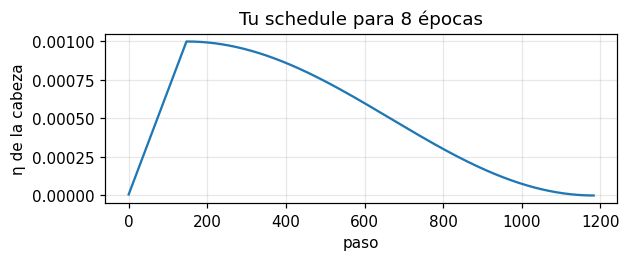

In [15]:
steps_per_epoch = math.ceil(len(y_train) / BATCH)
_m_ = my_model()
_opt, _sched = my_opt(_m_, 8 * steps_per_epoch)
assert isinstance(_opt, torch.optim.AdamW) and len(_opt.param_groups) == 2, 'Esperaba AdamW con dos grupos.'
lr_fc = [g['lr'] for g in _opt.param_groups if any(p is _m_.fc.weight for p in g['params'])]
lr_rest = [g['lr'] for g in _opt.param_groups if not any(p is _m_.fc.weight for p in g['params'])]
assert lr_fc and lr_rest and lr_fc[0] > lr_rest[0], 'La cabeza debe tener un η mayor que el backbone.'
lrs = []
for _ in range(8 * steps_per_epoch):
    lrs.append(_opt.param_groups[-1]['lr']); _opt.step(); _sched.step()
peak = int(np.argmax(lrs))
assert lrs[0] <= 1.5 * max(lrs) / steps_per_epoch and abs(peak - steps_per_epoch) <= 2, 'Esperaba warmup lineal durante la primera época.'
assert lrs[-1] < 0.01 * max(lrs), 'Esperaba que η llegara casi a cero al final.'
plt.figure(figsize=(6, 2)); plt.plot(lrs); plt.xlabel('paso'); plt.ylabel('η de la cabeza'); plt.title('Tu schedule para 8 épocas'); plt.show()

In [16]:
params = {'estrategia': 'fine-tuning completo', 'arquitectura': 'resnet18 ImageNet', 'optimizador': 'AdamW',
          'lr_backbone': 1e-4, 'lr_cabeza': 1e-3, 'weight_decay': 0.05, 'schedule': 'warmup 1 época + coseno',
          'augment': 'espejo + rotaciones de 90° + traslación ±4 px', 'freeze_bn': True}
# freeze_bn: BatchNorm del backbone usa las μ y s² de ImageNet, como en el notebook 4, sección 4
run('2-mi-receta', my_model, my_opt, params, before_epoch=freeze_bn);


2-mi-receta: mejor época 6 · val_loss 0.0852 · val_acc 0.975 · F1 macro 0.974


## 7. Corrida 3 · Cambia una sola cosa · 5 min
Elige **un** cambio a tu receta y córrelo. Si escribes una función de modelo nueva, haz que su nombre termine en `_model` para que el despliegue la encuentre. Algunas opciones: la otra estrategia (probe o fine-tuning), sin augmentation, sin `freeze_bn`, `TRAIN_SIZE = 500`, o subir la imagen a 128×128 dentro del modelo con `nn.Upsample`. Antes de correrlo, escribe en `params` qué esperas que pase.

_Mi cambio y mi predicción:_ cambio **solo la estrategia**: *linear probe*, con el backbone congelado (`requires_grad = False`) y solo la cabeza `fc` entrenable. Todo lo demás es igual: mismos pesos de ImageNet, optimizador, schedule, augmentation y `freeze_bn`. Aquí `freeze_bn` es indispensable: sin él, BatchNorm seguiría actualizando sus promedios móviles en `train()` y el backbone no estaría de verdad congelado.

Predigo que la probe quedará **claramente por debajo** del fine-tuning en `best_val_acc` (unos 5 a 10 puntos), porque las features de ImageNet no están hechas para imágenes vistas desde arriba y aquí no se pueden adaptar. A cambio entrena unos 5 000 parámetros en lugar de ~11 millones, y cada época debería ser más rápida porque no hay backward por el backbone.


In [17]:
# Corrida 3: igual a la receta, pero con el backbone congelado (linear probe)
def probe_model():
    model = my_model()
    for name, p in model.named_parameters():
        if not name.startswith('fc.'):
            p.requires_grad = False          # solo W y b de la cabeza se entrenan
    return model

params_3 = {**params, 'estrategia': 'linear probe (backbone congelado)',
            'prediccion': 'val_acc 5-10 puntos por debajo del fine-tuning, con ~5 mil parámetros entrenables'}
run('3-linear-probe', probe_model, my_opt, params_3, before_epoch=freeze_bn);


3-linear-probe: mejor época 7 · val_loss 0.2935 · val_acc 0.901 · F1 macro 0.898


## 8. Comparar en MLflow (listo)

In [18]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENT], order_by=['attributes.start_time ASC'])
runs = runs.drop_duplicates('tags.mlflow.runName', keep='last').set_index('tags.mlflow.runName')
cols = ['params.n_trainable', 'metrics.init_loss', 'metrics.best_epoch', 'metrics.best_val_loss', 'metrics.best_val_acc', 'metrics.best_val_macro_f1']
runs[cols].round(3)

,params.n_trainable,metrics.init_loss,metrics.best_epoch,metrics.best_val_loss,metrics.best_val_acc,metrics.best_val_macro_f1
tags.mlflow.runName,,,,,,
1-cnn-desde-cero,288746,2.304,6.0,0.267,0.910,0.908
2-mi-receta,11181642,2.739,6.0,0.085,0.975,0.974
3-linear-probe,5130,2.739,7.0,0.293,0.901,0.898


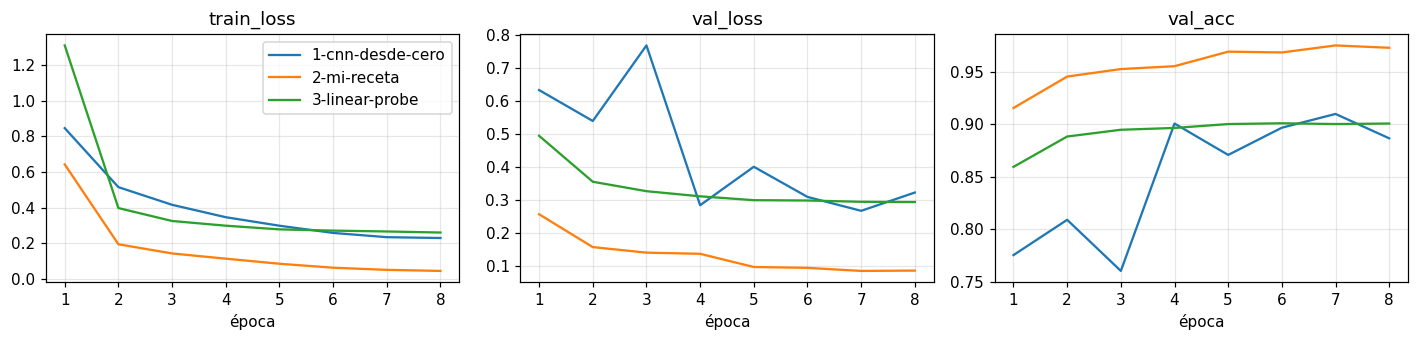

In [19]:
client = mlflow.MlflowClient()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for name, r in runs.iterrows():
    for ax, key in zip(axes, ['train_loss', 'val_loss', 'val_acc']):
        hist = client.get_metric_history(r.run_id, key)
        ax.plot([m.step + 1 for m in hist], [m.value for m in hist], label=name)
for ax, key in zip(axes, ['train_loss', 'val_loss', 'val_acc']):
    ax.set(title=key, xlabel='época')
axes[0].legend(); fig.tight_layout(); plt.show()

**Opcional · interfaz web.** En local, ejecuta `mlflow ui --backend-store-uri sqlite:///mlflow.db` y abre http://127.0.0.1:5000. En Kaggle o Colab, descarga `mlflow.db` y `mlruns/` y abre la interfaz en tu máquina.

## 9. Evaluar en prueba una sola vez (listo)
Se elige la corrida por `best_val_loss`, **nunca** por la prueba, y se carga su `best.pt` **desde MLflow**.

In [20]:
chosen = runs.sort_values('metrics.best_val_loss').iloc[0]
print('Corrida elegida:', chosen.name)
ckpt = torch.load(mlflow.artifacts.download_artifacts(run_id=chosen.run_id, artifact_path='best.pt'), map_location='cpu', weights_only=False)
BUILDERS = {f.__name__: f for f in [baseline_model, my_model] + [v for v in globals().values() if callable(v) and getattr(v, '__name__', '').endswith('_model')]}
model = BUILDERS[ckpt['model']](); model.load_state_dict(ckpt['state_dict']); model.to(device).eval()
test_metrics, pred_test = evaluate(model, X_test, y_test)
with mlflow.start_run(run_id=chosen.run_id):
    mlflow.log_metrics({f'test_{k}': v for k, v in test_metrics.items()})
print({k: round(v, 4) for k, v in test_metrics.items()})

Corrida elegida: 2-mi-receta


{'loss': 0.0715, 'acc': 0.976, 'macro_f1': 0.9748}


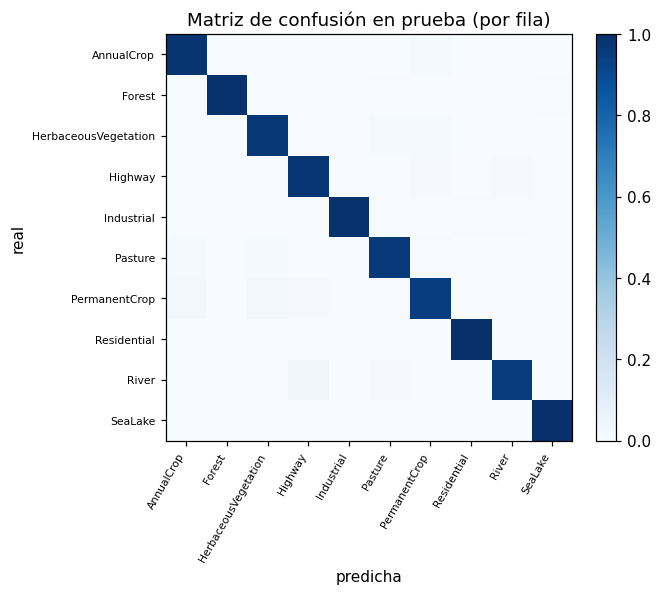

In [21]:
cm = confusion_matrix(y_test, pred_test, normalize='true')
plt.figure(figsize=(5.5, 4.8)); plt.imshow(cm, cmap='Blues', vmin=0, vmax=1); plt.colorbar(fraction=0.046)
plt.xticks(range(C), CLASSES, rotation=60, ha='right', fontsize=7); plt.yticks(range(C), CLASSES, fontsize=7)
plt.xlabel('predicha'); plt.ylabel('real'); plt.title('Matriz de confusión en prueba (por fila)'); plt.grid(False); plt.show()

## 10. TODO 4 · Despliegue: predecir sobre imágenes crudas · 10 min
Escribe `predict_raw(ckpt, images)`. Recibe una **lista de imágenes PIL**, como las que llegarían de un usuario, y devuelve un `DataFrame` con `clase` (el nombre) y `confianza`. Usa solo lo que trae `ckpt`:

1. `validate_image(img, ckpt['contract'])` para cada imagen, y apilar;
2. normalizar con `ckpt['mean']` y `ckpt['std']`;
3. reconstruir el modelo con `BUILDERS[ckpt['model']]()`, cargar los pesos y ponerlo en `eval()`;
4. aplicar softmax y elegir la clase.

In [22]:
@torch.no_grad()
def predict_raw(ckpt, images):
    # TODO 4 · usa solo lo que trae ckpt
    contract = ckpt['contract']
    # 1. validar cada imagen con el contrato y apilar: N × 3 × 64 × 64, uint8
    X = torch.stack([validate_image(img, contract) for img in images])
    # 2. normalizar con la μ y s guardadas en el checkpoint
    mean = torch.tensor(ckpt['mean'], device=device).view(1, 3, 1, 1)
    std = torch.tensor(ckpt['std'], device=device).view(1, 3, 1, 1)
    # 3. reconstruir el modelo, cargar θ* y ponerlo en eval(): BatchNorm con promedios móviles, sin aleatoriedad
    model = BUILDERS[ckpt['model']]()
    model.load_state_dict(ckpt['state_dict'])
    model.to(device).eval()
    # 4. softmax y clase más probable, por bloques para no llenar la memoria de la GPU
    probs = []
    for i in range(0, len(X), 512):
        xb = (X[i:i + 512].to(device).float() / 255 - mean) / std
        probs.append(torch.softmax(model(xb).float(), dim=1).cpu())
    conf, idx = torch.cat(probs).max(dim=1)
    return pd.DataFrame({'clase': [contract['classes'][k] for k in idx.tolist()], 'confianza': conf.numpy()})


In [23]:
to_pil = transforms.ToPILImage()
raw_test = [to_pil(x) for x in X_test]                          # imágenes crudas de prueba, como PIL

out = predict_raw(ckpt, raw_test)
agree = (out['clase'].map(CLASSES.index).to_numpy() == pred_test).mean()
print(f'1. Consistencia con la evaluación de prueba: {agree:.2%}')
assert agree > 0.999, 'El artefacto no reproduce las predicciones: ¿falta eval() o la normalización?'

for bad in [raw_test[0].convert('L'), raw_test[0].resize((32, 32))]:
    try:
        predict_raw(ckpt, [bad]); raise AssertionError('Una imagen inválida debió ser rechazada.')
    except ValueError as e:
        print('2. Contrato: imagen rechazada →', e)

pd.concat([pd.DataFrame({'real': [CLASSES[i] for i in y_test[:1000]]}), out.head(1000)], axis=1).to_csv('predicciones.csv', index=False)
print('3. predicciones.csv escrito'); out.head()

1. Consistencia con la evaluación de prueba: 100.00%
2. Contrato: imagen rechazada → Se esperaba una imagen RGB, llegó L.
2. Contrato: imagen rechazada → Se esperaba [64, 64], llegó [32, 32].
3. predicciones.csv escrito


,clase,confianza
0,Industrial,0.999587
1,AnnualCrop,0.999158
2,HerbaceousVegetation,0.999995
3,SeaLake,0.999999
4,HerbaceousVegetation,0.986811


## 11. Preguntas y entrega
1. ¿Se cumplió tu predicción para la línea base? ¿Qué número del registro de MLflow lo muestra?
2. ¿Ayudó ImageNet con imágenes satelitales? Compara la línea base con tu receta en `best_val_acc` **y** en `n_trainable`.
3. ¿Qué transformaciones pusiste en `augment` y por qué no cambian la clase en EuroSAT? ¿Cuál de ellas estaría mal en CIFAR-10?
4. Mira la matriz de confusión: ¿qué pares de clases se confunden más? ¿Te parece razonable viendo las imágenes?
5. ¿Qué pasaría en producción si alguien enviara imágenes de 128×128 de otro satélite? ¿Qué hace hoy `predict_raw` y qué debería hacer?

_Respuestas:_

1. **Línea base.** Sí, se cumplió. Predije una `val_acc` cercana a 0.90 y MLflow registra `best_val_acc` = **0.910** (F1 macro 0.908, `best_val_loss` 0.267). Las curvas de la sección 8 muestran que llegar ahí fue inestable: la `val_loss` sube de 0.54 a 0.77 en la tercera época (con `val_acc` de 0.76) y en la última la `val_acc` vuelve a bajar a ~0.89. Adam con η = 10⁻³ constante, sin schedule, oscila al final, y el early stopping guardó la mejor época (la 6, contando desde 0). Una CNN de 289 mil parámetros entrenada desde cero aprende bien las texturas de EuroSAT, pero queda lejos del transfer learning.

2. **¿Ayudó ImageNet?** Sí, y mucho, pero solo cuando se deja adaptar el backbone:

   | Corrida | `n_trainable` | `best_val_acc` | `best_val_loss` |
   |---|---:|---:|---:|
   | 1 · CNN desde cero | 288 746 | 0.910 | 0.267 |
   | 2 · fine-tuning ResNet-18 (mi receta) | 11 181 642 | **0.975** | **0.085** |
   | 3 · linear probe ResNet-18 | 5 130 | 0.901 | 0.293 |

   El fine-tuning gana 6.5 puntos de accuracy a la CNN desde cero y divide su `val_loss` por 3. Ya en la primera época tiene 0.915, más que el mejor resultado de la línea base en todo el entrenamiento. En prueba se mantiene: accuracy 0.976 y F1 macro 0.975. El costo es entrenar 39 veces más parámetros que la línea base. La linear probe muestra la otra cara: con solo 5 130 parámetros (56 veces menos que la línea base) llega a 0.901, casi lo mismo que la CNN desde cero, pero queda 7.4 puntos por debajo del fine-tuning, dentro de los 5 a 10 que predije en la sección 7. Las features de ImageNet, congeladas, ya separan bastante bien los usos del suelo, pero como las imágenes vistas desde arriba no se parecen a ImageNet, hay que dejar que el backbone se adapte para sacar el resto.

3. **Augmentation.** Usé un espejo horizontal, rotaciones de 0°, 90°, 180° y 270° (que con el espejo cubren las 8 orientaciones del cuadrado) y una traslación de hasta ±4 píxeles con bordes por reflexión. Ninguna cambia la clase en EuroSAT porque la foto se toma **desde arriba**: la escena no tiene una orientación canónica. Un río rotado sigue siendo un río y un cultivo reflejado sigue siendo un cultivo; la traslación solo mueve unos metros una escena que ya es homogénea en sus 64×64 píxeles. No toqué el color porque sí lleva información de la clase (agua, vegetación, suelo desnudo). En CIFAR-10 estarían mal las **rotaciones de 90°/180°** y, en general, el **espejo vertical**: las fotos de CIFAR-10 se toman de lado, con el cielo arriba y el suelo abajo, y un caballo o un barco de cabeza son imágenes que el modelo nunca verá en prueba (*Tu turno* 3 del notebook 3). El espejo horizontal y la traslación sí son válidos en los dos conjuntos.

4. **Matriz de confusión.** La diagonal está por encima de 0.94 en todas las clases y las confusiones son pocas. Los valores siguientes son aproximados, leídos de los colores de la figura. Los pares que más se confunden son: (a) **River → Highway** (~4 % de los ríos), porque a 64×64 píxeles los dos son una franja lineal que atraviesa la imagen sobre un fondo de vegetación, y solo cambian un poco el color y el ancho. (b) **PermanentCrop → HerbaceousVegetation** (~3 %) y **PermanentCrop → AnnualCrop** (~2 %). PermanentCrop es la clase con peor recall (~94 %): un cultivo permanente (huertos, viñedos), un cultivo anual y la vegetación herbácea son todos parches verdes y marrones con texturas parecidas. (c) Hay confusiones menores, de ~1–2 %, entre Pasture, HerbaceousVegetation y AnnualCrop. Me parece razonable viendo las imágenes de la sección 1: las clases con textura o color propios casi no se confunden (Residential ~99.7 %, SeaLake ~99 %, Industrial y Forest ~99 %), y los errores se concentran entre clases que se ven parecidas en una foto de 640 m × 640 m.

5. **Imágenes de 128×128 de otro satélite.** Hoy `predict_raw` las **rechaza**: `validate_image` lanza `ValueError("Se esperaba [64, 64], llegó [128, 128]")`, igual que en la verificación 2 de la sección 10. Es lo correcto como primera defensa, porque el modelo nunca vio esa escala: en Sentinel-2 un píxel son ~10 m, y otro satélite con otra resolución y otra respuesta espectral produce texturas y colores distintos aunque la escena sea la misma. Si se redimensionara a 64×64 sin más, el modelo respondería con una confianza que no merece. Lo que debería hacer: (a) ampliar el **contrato** con la fuente (sensor y resolución en m/píxel) y rechazar con un mensaje claro lo que no sea Sentinel-2 RGB a 10 m; (b) si es el mismo sensor con un recorte más grande, partir la imagen en 4 parches de 64×64 y combinar las predicciones; (c) si es otro sensor, remuestrear a 10 m/píxel y **vigilar el cambio de distribución**, por ejemplo la confianza media frente a la de prueba. Para usarlo en serio habría que reunir algunas imágenes etiquetadas del satélite nuevo y hacer fine-tuning.

**Entrega (evento evaluativo 2, Parte B):** este notebook ejecutado, con las salidas visibles, los 4 TODO resueltos y las respuestas de arriba, en la carpeta `evento2/` del repositorio de la pareja (uno solo para todo el curso). Detalles en [`evaluations/event_2`](../../../evaluations/event_2/README.md).

**Si quieres ir más allá:** busca con Optuna (sesión 02, notebook 5) el $\eta$ del backbone y de la cabeza; o prueba el ViT-B/16 preentrenado del notebook 5 como backbone, subiendo las imágenes a 224×224.